In [2]:
import pandas as pd
import requests

In [22]:
with open("../.config/av") as f:
    API_KEY = f.readline().strip()

BASE_URL = "https://www.alphavantage.co/query"

user_input_stock_symbol = input("Enter stock symbol: ")

params = {
    "function": "TIME_SERIES_DAILY",
    "symbol":  str(user_input_stock_symbol).upper().strip(),
    "apikey": str(API_KEY)
}

response = requests.get(BASE_URL, params=params)
data = response.json()
print(data)


{'Meta Data': {'1. Information': 'Daily Prices (open, high, low, close) and Volumes', '2. Symbol': 'HTZ', '3. Last Refreshed': '2026-11-13', '4. Output Size': 'Compact', '5. Time Zone': 'US/Eastern'}, 'Time Series (Daily)': {'2026-11-13': {'1. open': '1.5600', '2. high': '1.5600', '3. low': '1.4800', '4. close': '1.5000', '5. volume': '32174668'}, '2026-11-12': {'1. open': '1.5800', '2. high': '1.6200', '3. low': '1.5300', '4. close': '1.5400', '5. volume': '18984291'}, '2026-11-11': {'1. open': '1.5100', '2. high': '1.6500', '3. low': '1.4800', '4. close': '1.6400', '5. volume': '28602342'}, '2026-11-10': {'1. open': '1.6100', '2. high': '1.6200', '3. low': '1.4850', '4. close': '1.5000', '5. volume': '25744885'}, '2026-11-09': {'1. open': '1.6550', '2. high': '1.7000', '3. low': '1.6000', '4. close': '1.6300', '5. volume': '20523098'}, '2026-11-06': {'1. open': '1.8500', '2. high': '1.8500', '3. low': '1.6200', '4. close': '1.6400', '5. volume': '29803921'}, '2026-11-05': {'1. open':

In [38]:
api_symbol = data['Meta Data']['2. Symbol']

time_series = data.get('Time Series (Daily)', {})
df = pd.DataFrame.from_dict(time_series, orient='index')
df = df.rename(columns={
    "1. open": "open",
    "2. high": "high",
    "3. low": "low",
    "4. close": "close",
    "5. volume": "volume"
})
df = df.astype(float)

price_cols = ["open", "high", "low", "close"]
df[price_cols] = df[price_cols].round(2)
df.index = pd.to_datetime(df.index)
df = df.sort_index(ascending=False)
df.insert(0, "symbol", api_symbol.upper())

print("symbol: ", api_symbol.upper())
print(df.head())

symbol:  HTZ
           symbol  open  high   low  close      volume
2026-11-13    HTZ  1.56  1.56  1.48   1.50  32174668.0
2026-11-12    HTZ  1.58  1.62  1.53   1.54  18984291.0
2026-11-11    HTZ  1.51  1.65  1.48   1.64  28602342.0
2026-11-10    HTZ  1.61  1.62  1.48   1.50  25744885.0
2026-11-09    HTZ  1.66  1.70  1.60   1.63  20523098.0


In [40]:
import matplotlib.pyplot as plt

HTZ


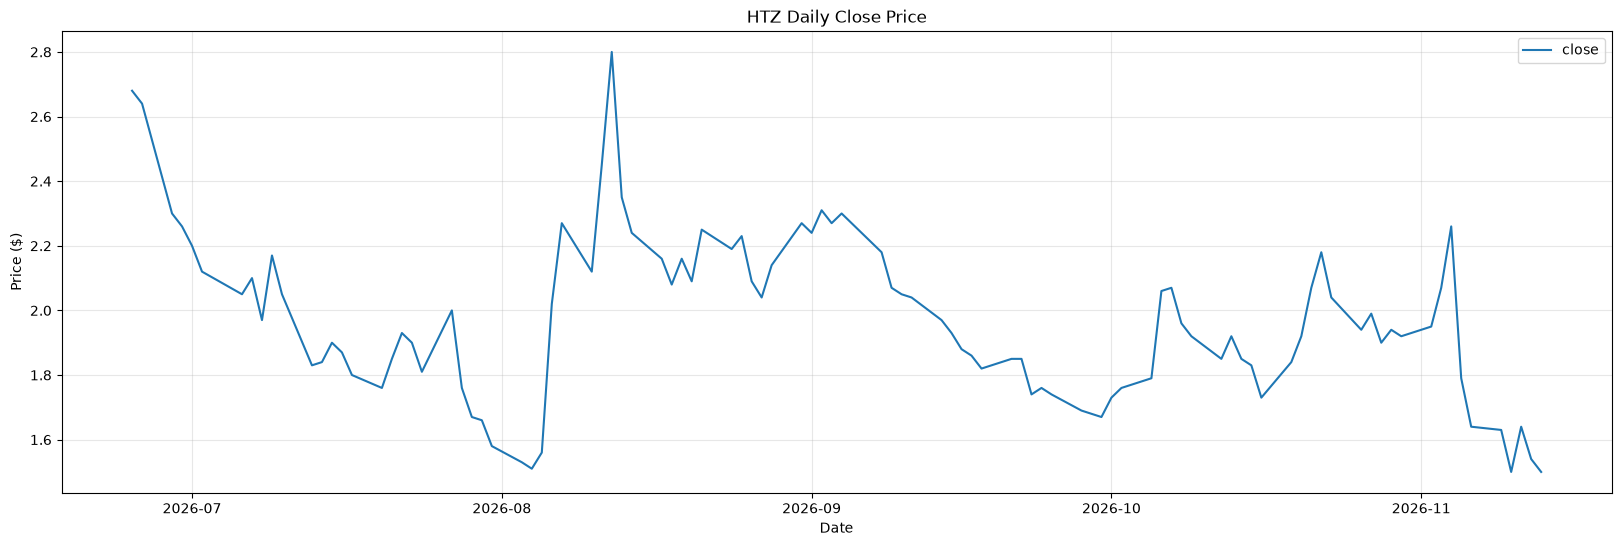

In [60]:
plt.figure(figsize=(20, 6))
plt.plot(df["close"], label="close")
plt.title(f"{df["symbol"].iloc[0]} Daily Close Price")
plt.xlabel("Date")
plt.ylabel("Price ($)")
plt.grid(True, alpha=0.3)
plt.legend()

print(df["symbol"].iloc[0])

plt.show()